# India's Digital Payments Boom: A Data Analysis of RBI Transaction Trends (2020–2025)

**Author:** Sherin Kunjumon  
**Domain:** Finance / Digital Payments  
**Tools:** Python (pandas, NumPy, matplotlib, seaborn, SciPy)

## Introduction

### Background
Digital payments have changed how people and businesses in India move money. Systems such as **UPI** now handle everything from tea-stall payments to bill settlements, while systems such as **RTGS** and **NEFT** carry large bank-to-bank transfers. Understanding how these systems have grown, and how they differ, helps banks, fintech companies and policy makers decide where to invest and what to expect.

### Problem statement
How has India's digital payment ecosystem evolved between 2020 and 2025, and how do UPI and other payment modes compare in volume, value and growth?

### Objectives
1. Measure the growth of UPI in transaction volume and value
2. Compare the payment systems by volume, value and average transaction size
3. Find patterns by month, weekday and season
4. Study how cards, bill payments, tolls and ATM withdrawals have changed
5. Summarise findings as clear insights and recommendations

### Dataset
Reserve Bank of India (RBI) **daily digital payments** data: 1,768 daily records and 50 columns, from 1 June 2020 to 31 January 2025. Every payment system has a `_vol` column (volume, in **lakh** transactions) and a `_val` column (value, in **INR crore**). Column meanings come from the codebook that ships with the dataset.

### Payment systems in the data
| System | What it is |
|---|---|
| UPI | Instant mobile payments between bank accounts |
| RTGS | Real-time transfers for large-value payments |
| NEFT | Bank-to-bank fund transfers |
| IMPS | Instant interbank transfers, available round the clock |
| NACH | Bulk and recurring credits and debits (salaries, EMIs, subsidies) |
| AePS | Aadhaar-based banking at micro-ATMs |
| FASTag (NETC) | Electronic toll collection |
| BBPS | Bharat Bill Payment System for utility and other bills |
| CTS | Cheque truncation (cheque clearing) |
| Cards, ATM | Credit, debit and prepaid card payments at POS and e-commerce, and ATM withdrawals |

### Scope note
2020 contains only June–December and 2025 only January. Yearly comparisons and growth rates therefore use the full years **2021–2024**.

## Table of contents

- [Introduction](#introduction)
- [Setup](#setup)
- [1. Data loading and initial overview](#1-data-loading-and-initial-overview)
- [2. Data pre-processing](#2-data-pre-processing)
    - [2.1 Duplicates, data type and order](#21-duplicates-data-type-and-order)
    - [2.2 Dropping the combined card columns](#22-dropping-the-combined-card-columns)
    - [2.3 Handling missing values](#23-handling-missing-values)
    - [2.4 Derived columns](#24-derived-columns)
- [3. Exploratory data analysis and visualizations](#3-exploratory-data-analysis-and-visualizations)
    - [3.1 Univariate analysis: UPI volume and ticket size](#31-univariate-analysis-upi-volume-and-ticket-size)
    - [3.2 Trend: UPI monthly volume and value](#32-trend-upi-monthly-volume-and-value)
    - [3.3 Annual growth of UPI (full years 2021–2024)](#33-annual-growth-of-upi-full-years-20212024)
    - [3.4 Payment mix: volume vs value (2024)](#34-payment-mix-volume-vs-value-2024)
    - [3.5 Growth of other payment systems](#35-growth-of-other-payment-systems)
    - [3.6 Seasonality: average daily UPI volume by month](#36-seasonality-average-daily-upi-volume-by-month)
    - [3.7 Weekday pattern](#37-weekday-pattern)
    - [3.8 Average transaction size](#38-average-transaction-size)
    - [3.9 Correlation between payment systems](#39-correlation-between-payment-systems)
    - [3.10 UPI volume vs value](#310-upi-volume-vs-value)
    - [3.11 Card payments: credit vs debit](#311-card-payments-credit-vs-debit)
    - [3.12 UPI vs ATM withdrawals](#312-upi-vs-atm-withdrawals)
- [4. Key insights](#4-key-insights)
- [5. Conclusion and recommendations](#5-conclusion-and-recommendations)

## Setup
Import the libraries used throughout the notebook. If a library is missing, install it once from a terminal with `pip install pandas numpy matplotlib seaborn scipy ipykernel`, then restart the kernel.

The CSV file `rbi_daily_digital_payments.csv` must be in the **same folder** as this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'


# 1. Data loading and initial overview
Load the CSV with pandas and look at its size, data types and first rows.

In [2]:
df = pd.read_csv('rbi_daily_digital_payments.csv')
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1768, 50)


,id,date,rtgs_vol,rtgs_val,neft_vol,neft_val,aeps_vol,aeps_val,upi_vol,upi_val,...,ppis_card_at_pos_vol,ppis_card_at_pos_val,ppis_card_at_e_commerce_vol,ppis_card_at_e_commerce_val,government_securities_clearing_vol,government_securities_clearing_val,forex_clearing_vol,forex_clearing_val,rupee_derivatives_vol,rupee_derivatives_val
0,0,2020-06-01,4.85,436996.69,172.11,104275.13,0.44,7.68,476.97,10413.11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2020-06-02,4.54,361878.87,100.07,65259.02,0.44,7.67,476.78,9951.30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2020-06-03,4.30,330632.89,100.36,62985.75,0.44,7.48,456.26,9622.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2020-06-04,4.35,329072.45,94.66,63148.29,0.45,7.32,463.05,9639.50,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2020-06-05,4.56,365468.95,111.26,68932.72,0.48,7.32,464.79,9539.52,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df['date'] = pd.to_datetime(df['date'])      # text -> datetime
print("Date range:", df['date'].min().date(), "to", df['date'].max().date())
df.info()

Date range: 2020-06-01 to 2025-01-31
<class 'pandas.DataFrame'>
RangeIndex: 1768 entries, 0 to 1767
Data columns (total 50 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   id                                     1768 non-null   int64         
 1   date                                   1768 non-null   datetime64[us]
 2   rtgs_vol                               1724 non-null   float64       
 3   rtgs_val                               1724 non-null   float64       
 4   neft_vol                               1768 non-null   float64       
 5   neft_val                               1768 non-null   float64       
 6   aeps_vol                               1768 non-null   float64       
 7   aeps_val                               1768 non-null   float64       
 8   upi_vol                                1768 non-null   float64       
 9   upi_val                              

In [4]:
df.describe().T.head(15)

,count,mean,min,25%,50%,75%,max,std
id,1768.0,883.5,0.0,441.75,883.5,1325.25,1767.0,510.521955
date,1768,2022-10-28 04:28:46.696832,2020-06-01 00:00:00,2021-08-16 18:00:00,2022-11-01 12:00:00,2024-01-17 06:00:00,2025-01-31 00:00:00,NaN
rtgs_vol,1724.0,6.746317,0.0,4.715,7.655,9.29,18.76,3.466381
rtgs_val,1724.0,428596.832964,0.12,149138.0075,476380.29,636266.775,1589480.32,288158.768885
neft_vol,1768.0,163.588857,6.06,103.4225,154.165,222.3275,579.28,88.049347
neft_val,1768.0,94643.351437,2093.33,55476.665,101296.63,129771.8825,396593.31,56165.7402
aeps_vol,1768.0,0.579542,0.16,0.43,0.57,0.7,1.68,0.206991
aeps_val,1768.0,16.973382,4.31,13.235,16.88,20.36,44.22,6.008303
upi_vol,1768.0,2626.210062,289.0,1149.675,2412.11,4021.6375,6441.18,1593.878378
upi_val,1768.0,40640.309531,4333.74,20526.94,38757.3,58143.755,95915.61,22065.106467


### Initial observations
- The dataset has **1,768 rows and 50 columns** covering 1 June 2020 to 31 January 2025.
- Apart from `id` and `date`, all columns are numeric (float).
- Many columns have fewer non-null values than rows (for example cheque clearing, NACH, card payments, forex and derivatives), so missing values need a closer look.
- The scales are very different: RTGS values run into lakhs of crores, while AePS values are only a few crore. This is why the charts later use shares, ratios and indexed values to compare systems.

# 2. Data pre-processing
Problems to check: **duplicates, row order, data types, missing values**, and then create **derived columns**.

### 2.1 Duplicates, data type and order
- `date` was converted from text to datetime (see above).
- A normal `df.duplicated()` returns 0, because the `id` column is different on every row. So duplicates are checked on **all columns except `id`**. This finds exact copies of rows from Aug 2024 to Jan 2025.
- The data is then sorted by date, because some rows were out of order and a time-series analysis needs the correct order.

In [5]:
# The id column is different on every row, so check duplicates on all OTHER columns
cols = [c for c in df.columns if c != 'id']
print("Duplicate rows (ignoring id):", df.duplicated(subset=cols).sum())

df = df.drop_duplicates(subset=cols).sort_values('date').reset_index(drop=True)
print("Shape after cleaning:", df.shape, "| each date appears once:", df['date'].is_unique)

Duplicate rows (ignoring id): 62
Shape after cleaning: (1706, 50) | each date appears once: True


### 2.2 Dropping the combined card columns
The six `*_pos_and_e_commerce_*` columns are only filled for Nov 2020 – Sep 2021. From Oct 2021 the same information is reported in separate POS and e-commerce columns. More than 80% of the combined columns are empty, so they are dropped rather than filled.

In [6]:
# Combined card columns exist only for Nov 2020 - Sep 2021 (replaced by separate POS / e-commerce columns)
combined = [c for c in df.columns if 'pos_and_e_commerce' in c]
df = df.drop(columns=combined)
print("Dropped", len(combined), "columns. New shape:", df.shape)

Dropped 6 columns. New shape: (1706, 44)


### 2.3 Handling missing values
The blanks are **not random errors**, so each case is treated according to its cause:

| Situation | Example | Treatment | Reason |
|---|---|---|---|
| System closed (weekends, bank holidays) | RTGS, cheque clearing, NACH | Fill with **0** | No transactions happened that day |
| Series had not started yet | Securities, forex, derivatives (before May 2021); POS and e-commerce card columns (before Oct 2021) | Leave as **missing** | Filling with 0 would wrongly claim there were no transactions, when the data was not reported |

The mean or median is not used to fill, because averaging transaction volumes would create numbers that never happened.

In [7]:
value_cols = [c for c in df.columns if c not in ('id', 'date')]

for c in value_cols:
    first_reported = df.loc[df[c].notna(), 'date'].min()
    # blank on/after the first reported date = system closed that day -> 0 transactions
    mask = df[c].isna() & (df['date'] >= first_reported)
    df.loc[mask, c] = 0

missing = df.isna().sum()
print("Columns that still have missing values (series not yet reported):")
missing[missing > 0]

Columns that still have missing values (series not yet reported):


credit_card_at_pos_vol                487
credit_card_at_pos_val                487
credit_card_at_e_commerce_vol         487
credit_card_at_e_commerce_val         487
debit_card_at_pos_vol                 487
debit_card_at_pos_val                 487
debit_card_at_e_commerce_vol          487
debit_card_at_e_commerce_val          487
ppis_card_at_pos_vol                  487
ppis_card_at_pos_val                  487
ppis_card_at_e_commerce_vol           487
ppis_card_at_e_commerce_val           487
government_securities_clearing_vol    336
government_securities_clearing_val    336
forex_clearing_vol                    336
forex_clearing_val                    336
rupee_derivatives_vol                 336
rupee_derivatives_val                 336
dtype: int64

### 2.4 Derived columns
- `year`, `month`, `month_name`, `quarter`, `weekday`: taken from the date for trend and seasonality analysis
- `is_weekend`: True for Saturday and Sunday
- `upi_avg_ticket`: average amount per UPI transaction in rupees = (value in crore × 1e7) ÷ (volume in lakh × 1e5)

In [8]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()
df['quarter'] = df['date'].dt.quarter
df['weekday'] = df['date'].dt.day_name()
df['is_weekend'] = df['date'].dt.dayofweek >= 5

# Average UPI ticket size in rupees: (crores x 1e7) / (lakhs x 1e5)
df['upi_avg_ticket'] = (df['upi_val'] * 1e7) / (df['upi_vol'] * 1e5)

df[['date', 'year', 'month_name', 'weekday', 'is_weekend', 'upi_avg_ticket']].head()

,date,year,month_name,weekday,is_weekend,upi_avg_ticket
0,2020-06-01,2020,June,Monday,False,2183.179236
1,2020-06-02,2020,June,Tuesday,False,2087.189060
2,2020-06-03,2020,June,Wednesday,False,2108.968571
3,2020-06-04,2020,June,Thursday,False,2081.740633
4,2020-06-05,2020,June,Friday,False,2052.436584


In [9]:
print(df.shape)
print("Missing cells left (all are series not yet reported):", df.isna().sum().sum())
df[['upi_vol', 'upi_val', 'upi_avg_ticket']].describe().round(1)

(1706, 51)
Missing cells left (all are series not yet reported): 7860


,upi_vol,upi_val,upi_avg_ticket
count,1706.0,1706.0,1706.0
mean,2534.3,39533.0,1658.9
std,1545.0,21570.2,260.9
min,289.0,4333.7,986.3
25%,1105.4,19857.7,1464.8
50%,2280.2,37306.9,1663.1
75%,3828.1,56383.3,1865.8
max,6441.2,95915.6,2338.4


The cleaned dataset has **one row per day (1,706 rows)**. Every remaining blank is a payment series that had not yet started being reported.

# 3. Exploratory data analysis and visualizations
> Note: 2020 contains only June–December and 2025 only January. For yearly comparisons and growth rates, only the full years **2021–2024** are used.

## 3.1 Univariate analysis: UPI volume and ticket size

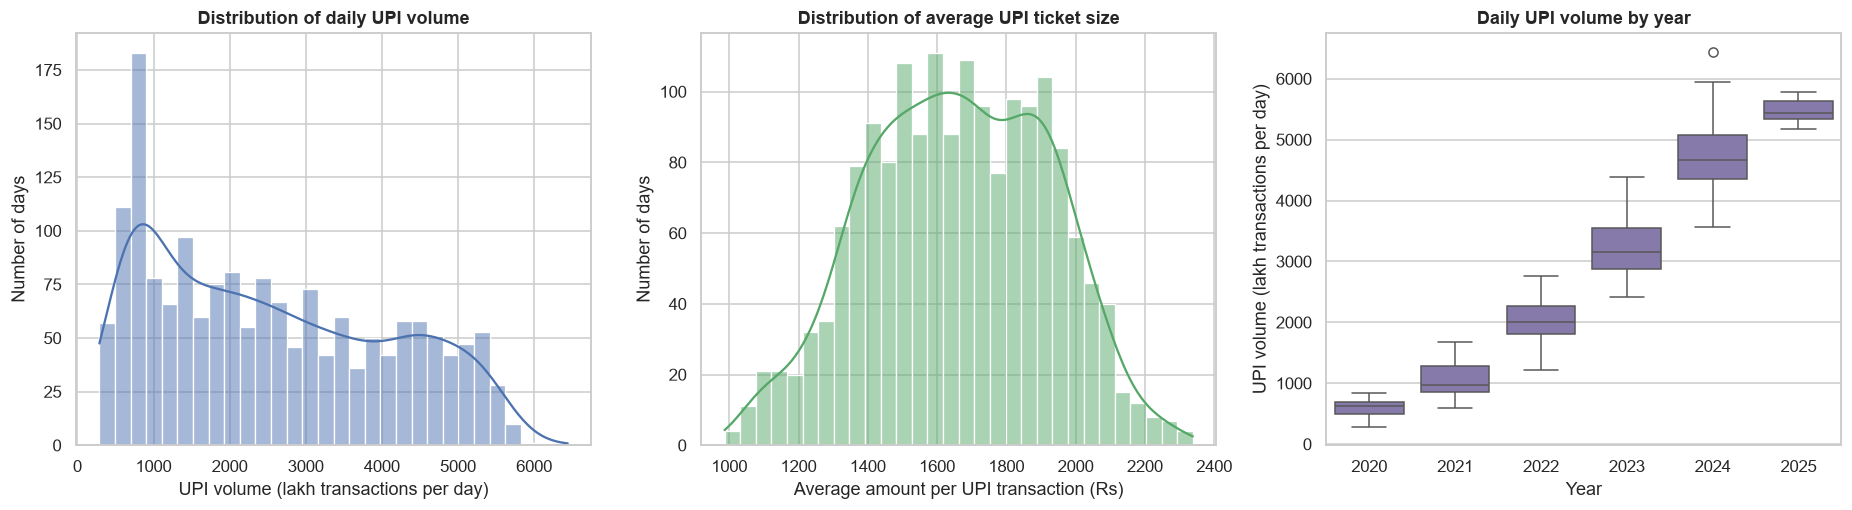

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.histplot(df['upi_vol'], bins=30, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('Distribution of daily UPI volume')
axes[0].set_xlabel('UPI volume (lakh transactions per day)')
axes[0].set_ylabel('Number of days')

sns.histplot(df['upi_avg_ticket'], bins=30, kde=True, ax=axes[1], color='#55A868')
axes[1].set_title('Distribution of average UPI ticket size')
axes[1].set_xlabel('Average amount per UPI transaction (Rs)')
axes[1].set_ylabel('Number of days')

sns.boxplot(x='year', y='upi_vol', data=df, ax=axes[2], color='#8172B2')
axes[2].set_title('Daily UPI volume by year')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('UPI volume (lakh transactions per day)')

plt.tight_layout()
plt.show()

**Interpretation:** Daily UPI volume is right-skewed with a long tail, because volumes grew steadily over the period, with early low-volume days at one end and recent high-volume days at the other. The boxplot shows this clearly, with the whole distribution moving up every year. The average UPI ticket size is spread between about ₹1,000 and ₹2,300 per transaction.

## 3.2 Trend: UPI monthly volume and value

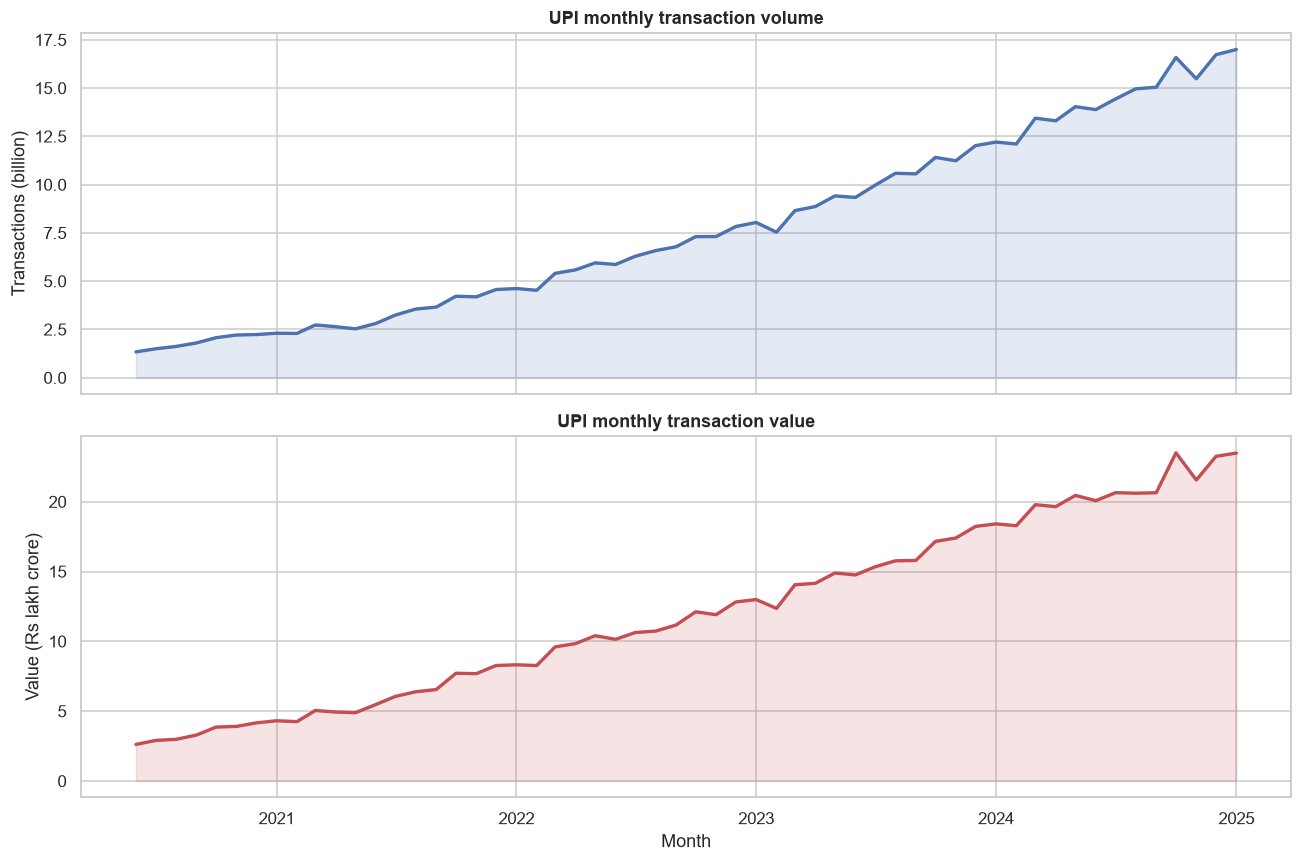

In [11]:
# Monthly totals. Volume: lakh -> billion (1 billion = 10,000 lakh). Value: crore -> Rs lakh crore (1 lakh crore = 1,00,000 crore)
monthly = df.groupby(df['date'].dt.to_period('M'))[['upi_vol', 'upi_val']].sum()
monthly.index = monthly.index.to_timestamp()
monthly['vol_bn'] = monthly['upi_vol'] / 1e4
monthly['val_lakh_cr'] = monthly['upi_val'] / 1e5

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(monthly.index, monthly['vol_bn'], color='#4C72B0', linewidth=2.2)
axes[0].fill_between(monthly.index, monthly['vol_bn'], alpha=0.15, color='#4C72B0')
axes[0].set_title('UPI monthly transaction volume')
axes[0].set_ylabel('Transactions (billion)')

axes[1].plot(monthly.index, monthly['val_lakh_cr'], color='#C44E52', linewidth=2.2)
axes[1].fill_between(monthly.index, monthly['val_lakh_cr'], alpha=0.15, color='#C44E52')
axes[1].set_title('UPI monthly transaction value')
axes[1].set_ylabel('Value (Rs lakh crore)')
axes[1].set_xlabel('Month')

plt.tight_layout()
plt.show()

**Interpretation:** Both volume and value of UPI rise steadily from 2020 to 2025 with only small short-term dips, showing sustained adoption rather than a one-off spike.

## 3.3 Annual growth of UPI (full years 2021–2024)

In [12]:
# Full calendar years only (2020 starts in June and 2025 has only January)
full = df[df['year'].between(2021, 2024)]
yearly = full.groupby('year')[['upi_vol', 'upi_val']].sum()
yearly['vol_bn'] = yearly['upi_vol'] / 1e4
yearly['val_lakh_cr'] = yearly['upi_val'] / 1e5
yearly['vol_growth_%'] = (yearly['vol_bn'].pct_change() * 100).round(1)
yearly['val_growth_%'] = (yearly['val_lakh_cr'].pct_change() * 100).round(1)
yearly[['vol_bn', 'val_lakh_cr', 'vol_growth_%', 'val_growth_%']].round(1)

,vol_bn,val_lakh_cr,vol_growth_%,val_growth_%
year,,,,
2021,38.7,71.6,NaN,NaN
2022,74.0,125.9,91.2,76.0
2023,117.6,182.9,58.8,45.2
2024,172.2,246.8,46.4,35.0


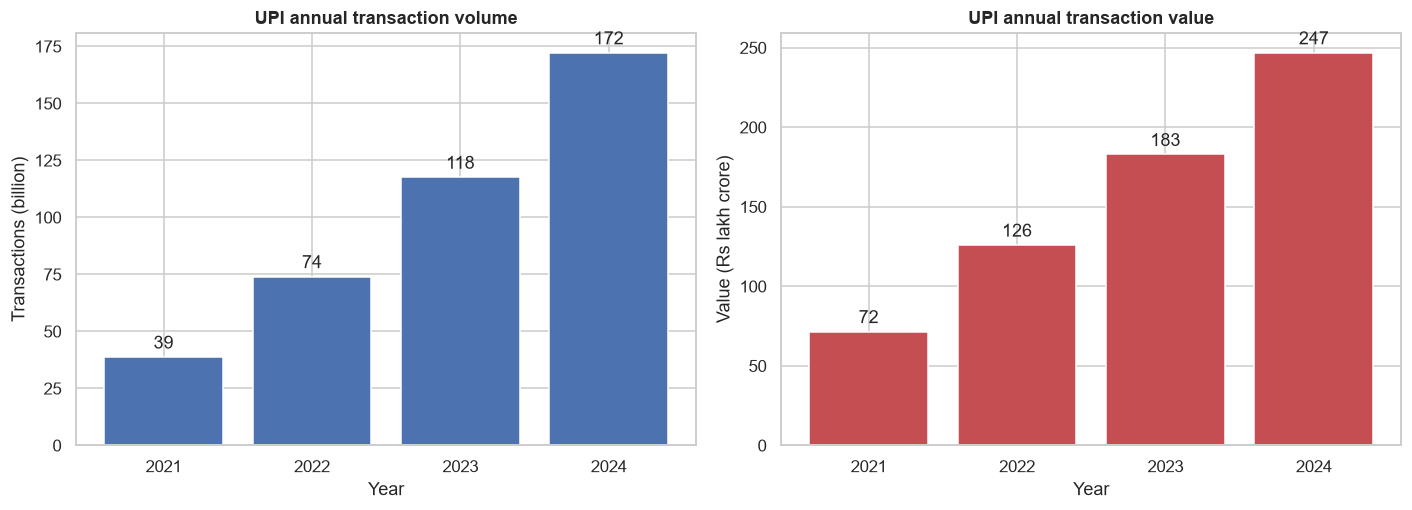

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

bars = axes[0].bar(yearly.index.astype(str), yearly['vol_bn'], color='#4C72B0')
axes[0].bar_label(bars, fmt='%.0f', padding=3)
axes[0].set_title('UPI annual transaction volume')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Transactions (billion)')

bars = axes[1].bar(yearly.index.astype(str), yearly['val_lakh_cr'], color='#C44E52')
axes[1].bar_label(bars, fmt='%.0f', padding=3)
axes[1].set_title('UPI annual transaction value')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Value (Rs lakh crore)')

plt.tight_layout()
plt.show()

**Interpretation:** UPI volume grew from about 39 billion transactions in 2021 to about 172 billion in 2024 (4.4×), and value from about ₹72 lakh crore to ₹247 lakh crore. Growth is still strong but slowing: volume growth was 91% in 2022, 59% in 2023 and 46% in 2024.

## 3.4 Payment mix: volume vs value (2024)

In [14]:
systems = {'UPI': 'upi', 'NEFT': 'neft', 'IMPS': 'imps', 'RTGS': 'rtgs',
           'NACH credit': 'nach_credit', 'NACH debit': 'nach_debit', 'Cheque (CTS)': 'cts',
           'FASTag': 'netc', 'BBPS': 'bbps', 'AePS': 'aeps'}

d24 = df[df['year'] == 2024]
vol24 = pd.Series({k: d24[f'{v}_vol'].sum() for k, v in systems.items()})
val24 = pd.Series({k: d24[f'{v}_val'].sum() for k, v in systems.items()})

share = pd.DataFrame({'volume_share_%': vol24 / vol24.sum() * 100,
                      'value_share_%': val24 / val24.sum() * 100}).round(1)
share.sort_values('volume_share_%', ascending=False)

,volume_share_%,value_share_%
UPI,85.5,8.8
NEFT,4.6,15.4
IMPS,2.9,2.5
NACH credit,2.4,0.8
FASTag,2.0,0.0
BBPS,1.1,0.3
NACH debit,0.9,0.7
Cheque (CTS),0.3,2.6
RTGS,0.1,69.0
AePS,0.0,0.0


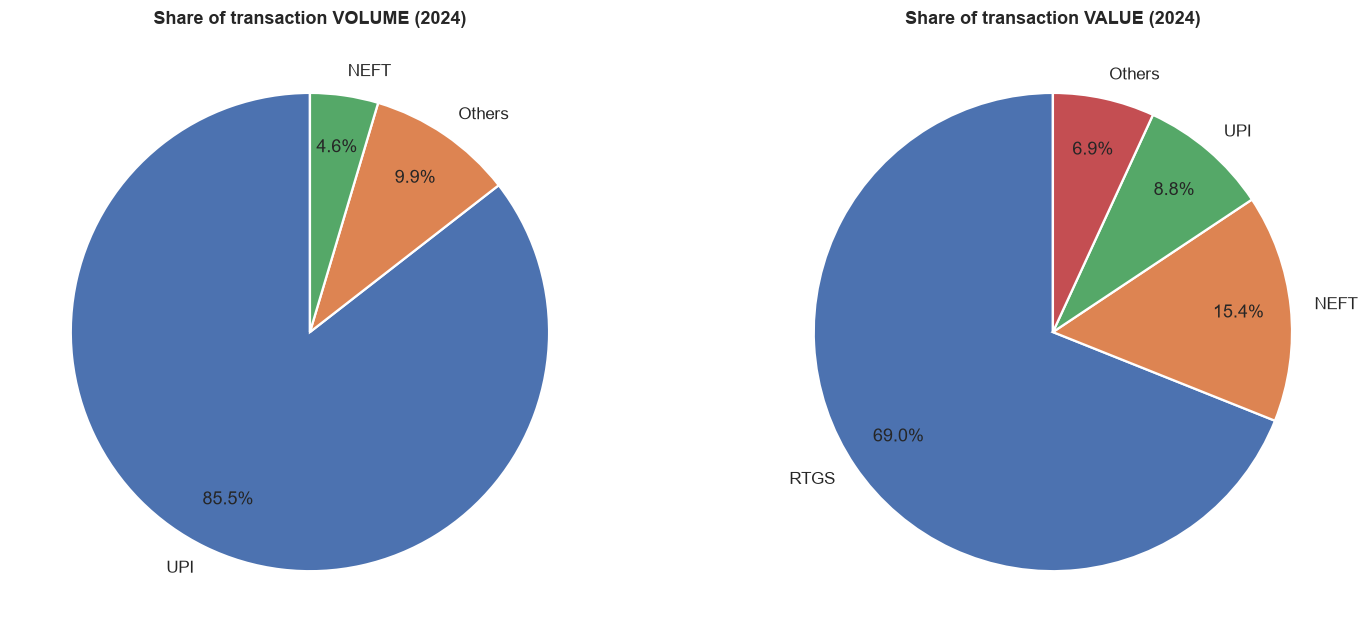

In [15]:
def group_small(s, threshold=3):
    """Group slices below the threshold (%) into 'Others' so the pie stays readable."""
    pct = s / s.sum() * 100
    out = s[pct >= threshold].copy()
    if (pct < threshold).any():
        out['Others'] = s[pct < threshold].sum()
    return out.sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = sns.color_palette('deep', 8)

for ax, data, title in [(axes[0], group_small(vol24), 'Share of transaction VOLUME (2024)'),
                        (axes[1], group_small(val24), 'Share of transaction VALUE (2024)')]:
    ax.pie(data, labels=data.index, autopct='%1.1f%%', startangle=90, colors=colors,
           wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}, pctdistance=0.78)
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Interpretation:** The two pies tell opposite stories. **UPI accounts for 85.5% of transactions but only 8.8% of value**, while **RTGS is just 0.1% of transactions but 69% of value**. UPI is the payment system of small everyday payments, and RTGS carries a few very large transfers.

## 3.5 Growth of other payment systems

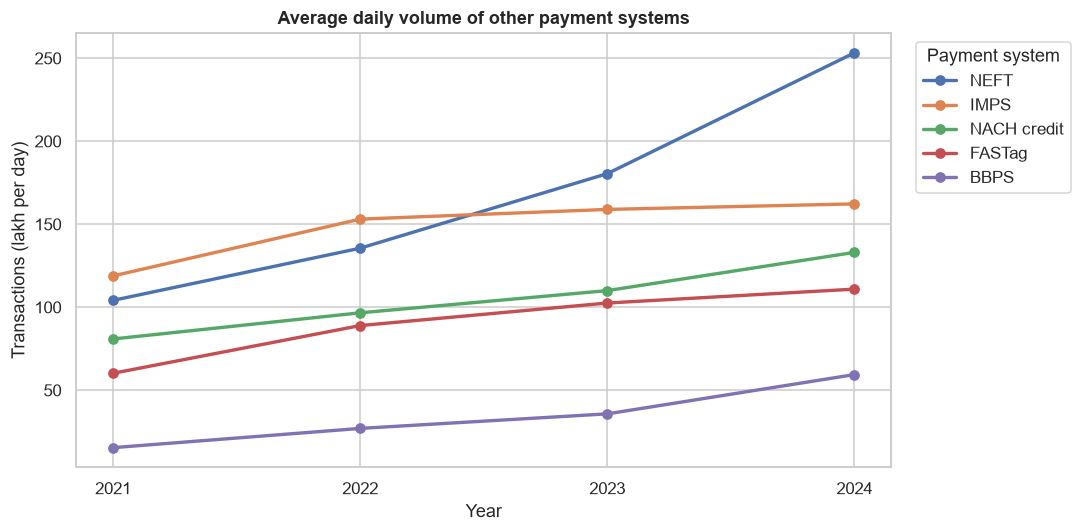

,NEFT,IMPS,NACH credit,FASTag,BBPS
year,,,,,
2021,104.1,118.9,80.9,60.2,15.4
2022,135.6,153.1,96.6,88.9,27.0
2023,180.5,158.9,110.0,102.5,35.8
2024,253.2,162.2,133.0,110.9,59.4


In [16]:
# Average daily volume of the other payment systems, full years only
others = {'NEFT': 'neft_vol', 'IMPS': 'imps_vol', 'NACH credit': 'nach_credit_vol',
          'FASTag': 'netc_vol', 'BBPS': 'bbps_vol'}
trend = full.groupby('year')[list(others.values())].mean()
trend.columns = list(others.keys())

ax = trend.plot(marker='o', linewidth=2.2, figsize=(10, 5))
ax.set_title('Average daily volume of other payment systems')
ax.set_xlabel('Year')
ax.set_ylabel('Transactions (lakh per day)')
ax.set_xticks(trend.index)
ax.legend(title='Payment system', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

trend.round(1)

**Interpretation:** Bill payments (BBPS) grew 3.9× between 2021 and 2024, NEFT 2.4× and FASTag 1.8×. IMPS flattened out (only +2% from 2023 to 2024), which suggests UPI is taking over some of what IMPS used to handle.

## 3.6 Seasonality: average daily UPI volume by month

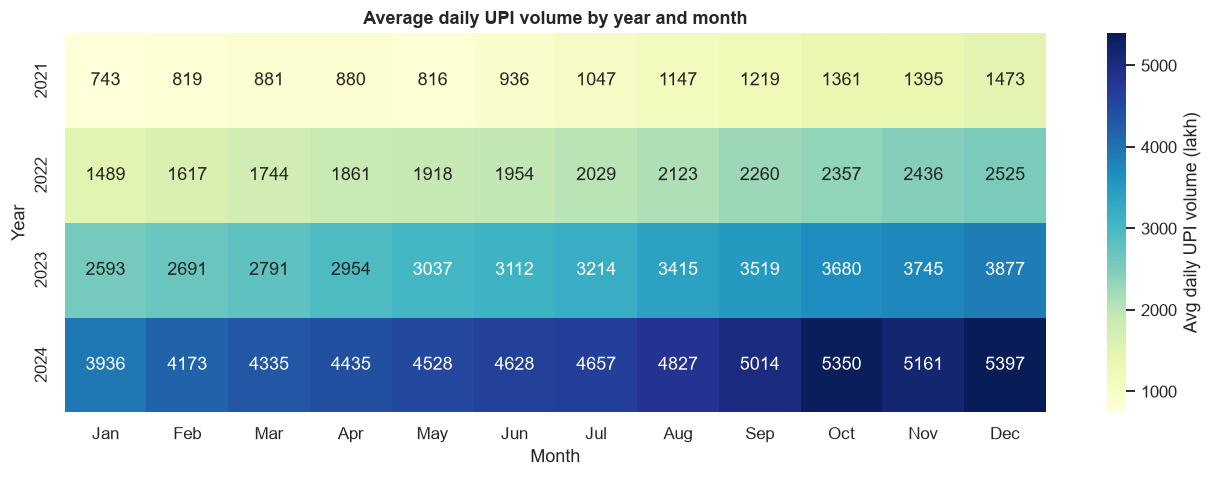

In [17]:
pivot = df[df['year'].between(2021, 2024)].pivot_table(values='upi_vol', index='year',
                                                         columns='month', aggfunc='mean')
pivot.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(12, 4.5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Avg daily UPI volume (lakh)'})
plt.title('Average daily UPI volume by year and month')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

**Interpretation:** Volume climbs through every year, with December the highest month in each of the four years. Part of this is the long-term growth trend, and part is the festive and year-end spending season. The busiest single day in the data is **31 October 2024 (about 6,441 lakh transactions)**, around the Diwali period.

## 3.7 Weekday pattern

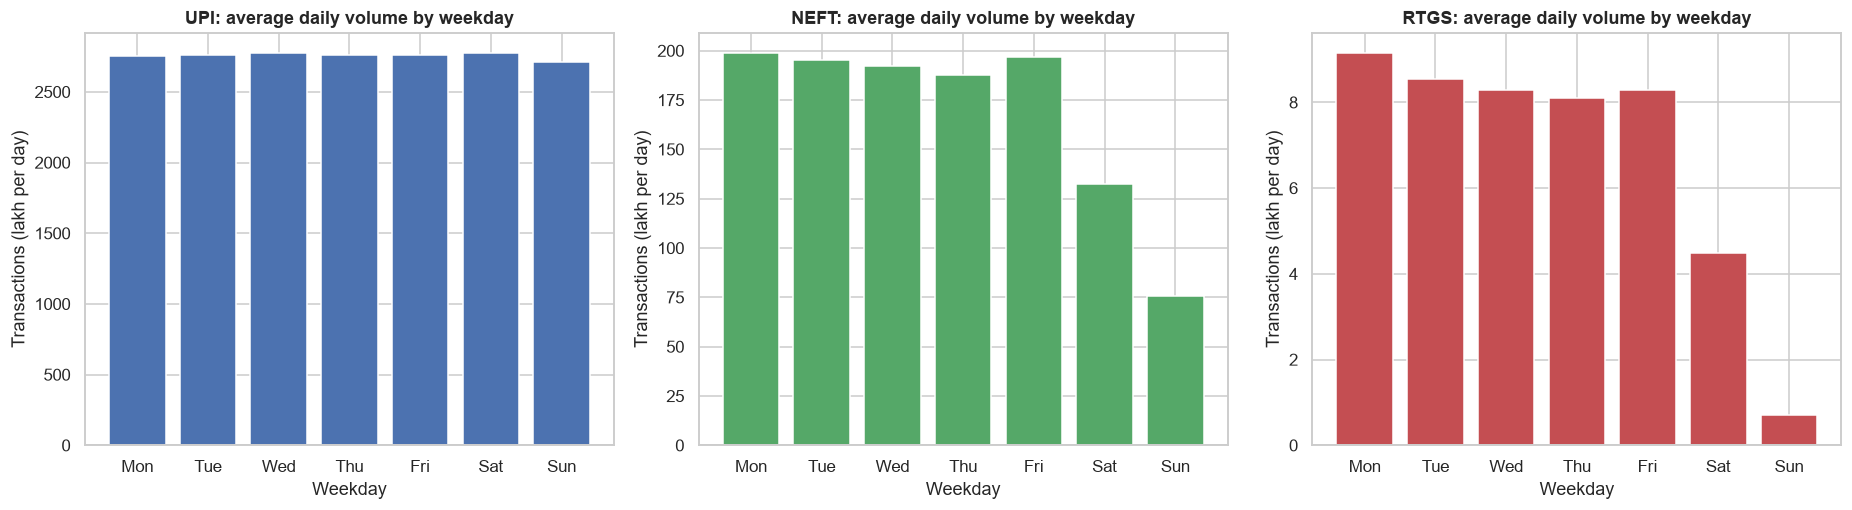

,upi_vol,neft_vol,rtgs_vol
weekday,,,
Monday,2750.1,198.9,9.2
Tuesday,2757.2,195.3,8.6
Wednesday,2776.4,192.1,8.3
Thursday,2761.1,187.9,8.1
Friday,2759.3,196.5,8.3
Saturday,2775.8,132.4,4.5
Sunday,2709.2,75.9,0.7


In [18]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
wk = df[df['year'].between(2021, 2024)].groupby('weekday')[['upi_vol', 'neft_vol', 'rtgs_vol']].mean().reindex(order)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col, title, color in zip(axes, ['upi_vol', 'neft_vol', 'rtgs_vol'],
                                 ['UPI', 'NEFT', 'RTGS'], ['#4C72B0', '#55A868', '#C44E52']):
    ax.bar(wk.index.str[:3], wk[col], color=color)
    ax.set_title(f'{title}: average daily volume by weekday')
    ax.set_xlabel('Weekday')
    ax.set_ylabel('Transactions (lakh per day)')

plt.tight_layout()
plt.show()
wk.round(1)

**Interpretation:** UPI is used almost equally on every day of the week (about 2,700–2,780 lakh per day), while NEFT and especially RTGS drop sharply on weekends: RTGS falls from about 9 lakh transactions on Monday to under 1 lakh on Sunday. This reflects business and bank-to-bank payments that follow working days, while consumer UPI payments do not.

## 3.8 Average transaction size

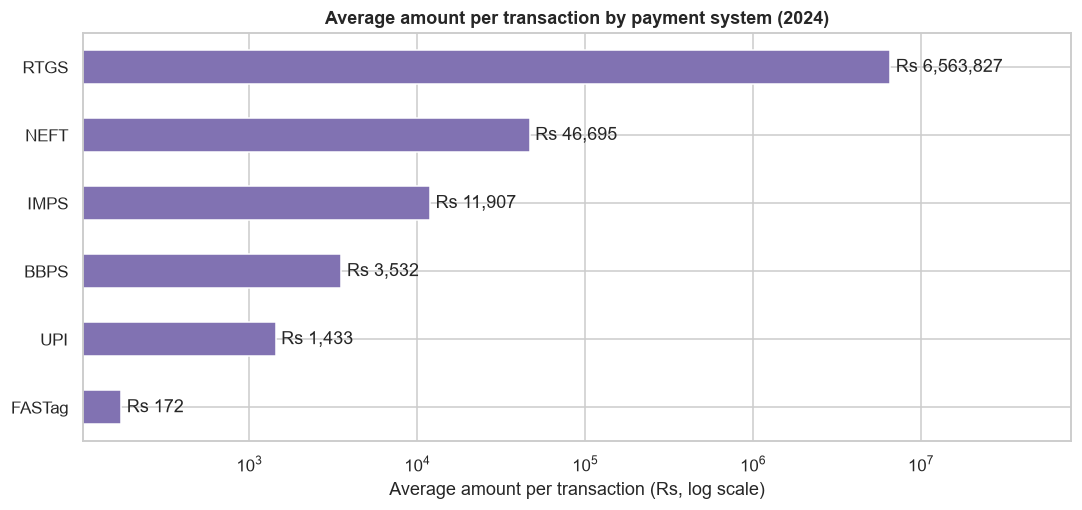

In [19]:
# Average amount per transaction in 2024 = total value / total volume  (crore x 1e7, lakh x 1e5)
ticket_systems = {'UPI': 'upi', 'IMPS': 'imps', 'NEFT': 'neft', 'RTGS': 'rtgs', 'BBPS': 'bbps', 'FASTag': 'netc'}
ticket = pd.Series({k: d24[f'{v}_val'].sum() * 1e7 / (d24[f'{v}_vol'].sum() * 1e5)
                    for k, v in ticket_systems.items()}).sort_values()

ax = ticket.plot(kind='barh', figsize=(10, 4.8), color='#8172B2', logx=True)
ax.set_title('Average amount per transaction by payment system (2024)')
ax.set_xlabel('Average amount per transaction (Rs, log scale)')
ax.set_ylabel('')
for i, v in enumerate(ticket):
    ax.text(v * 1.08, i, f'Rs {v:,.0f}', va='center')
ax.set_xlim(right=ticket.max() * 12)
plt.tight_layout()
plt.show()

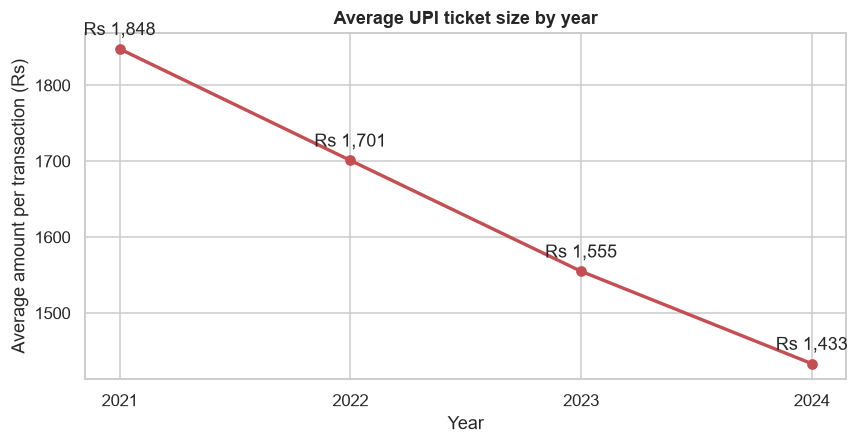

In [20]:
# Has the average UPI transaction become smaller over time?
upi_ticket = full.groupby('year').apply(lambda g: g['upi_val'].sum() * 1e7 / (g['upi_vol'].sum() * 1e5))

ax = upi_ticket.plot(marker='o', linewidth=2.2, figsize=(8, 4.2), color='#C44E52')
ax.set_title('Average UPI ticket size by year')
ax.set_xlabel('Year')
ax.set_ylabel('Average amount per transaction (Rs)')
ax.set_xticks(upi_ticket.index)
for x, y in upi_ticket.items():
    ax.annotate(f'Rs {y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 9), ha='center')
plt.tight_layout()
plt.show()

In [22]:
recent = df[df['year'].between(2023, 2024)]
wkend = recent.loc[recent['is_weekend'], 'upi_avg_ticket']
wkday = recent.loc[~recent['is_weekend'], 'upi_avg_ticket']

diff = wkend.mean() - wkday.mean()
se = np.sqrt(wkend.var() / len(wkend) + wkday.var() / len(wkday))
print(f"Weekend average ticket: Rs {wkend.mean():,.0f} | Weekday average ticket: Rs {wkday.mean():,.0f}")
print(f"Difference = Rs {diff:,.0f}, t-statistic = {diff / se:.2f}")

Weekend average ticket: Rs 1,331 | Weekday average ticket: Rs 1,561
Difference = Rs -230, t-statistic = -15.65


**Interpretation:** The average amount per transaction varies enormously between systems, from about ₹172 for FASTag toll payments to about ₹66 lakh for RTGS (on a log scale, so every gridline is 10× the one before). The average UPI payment has also **shrunk by about 22%, from ₹1,848 in 2021 to ₹1,433 in 2024**, so UPI is increasingly used for small payments. Weekend UPI payments are also smaller than weekday ones (about ₹1,331 vs ₹1,561 in 2023–2024), and the t-test shows the difference is statistically significant (p < 0.001).

## 3.9 Correlation between payment systems

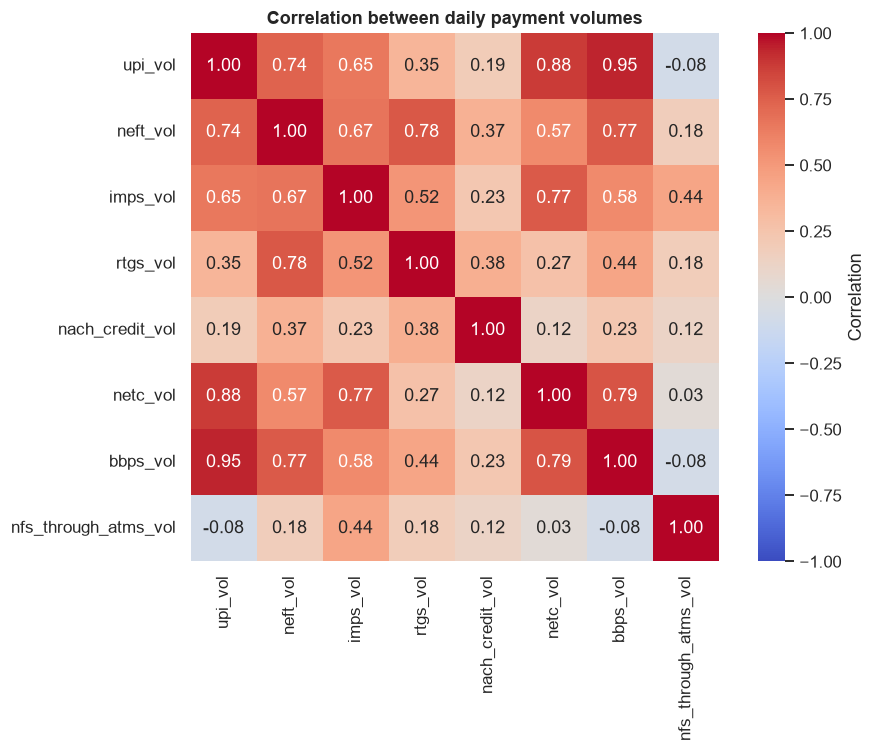

In [23]:
corr_cols = ['upi_vol', 'neft_vol', 'imps_vol', 'rtgs_vol', 'nach_credit_vol',
             'netc_vol', 'bbps_vol', 'nfs_through_atms_vol']
corr = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'Correlation'})
plt.title('Correlation between daily payment volumes')
plt.tight_layout()
plt.show()

**Interpretation:** UPI volume moves closely with bill payments (0.95) and FASTag (0.88), and also with NEFT (0.74). Correlation with ATM withdrawals is about zero (−0.08). **Caution:** most of these series trend upward over time, so a high correlation partly reflects that shared trend and does not by itself show cause and effect.

## 3.10 UPI volume vs value

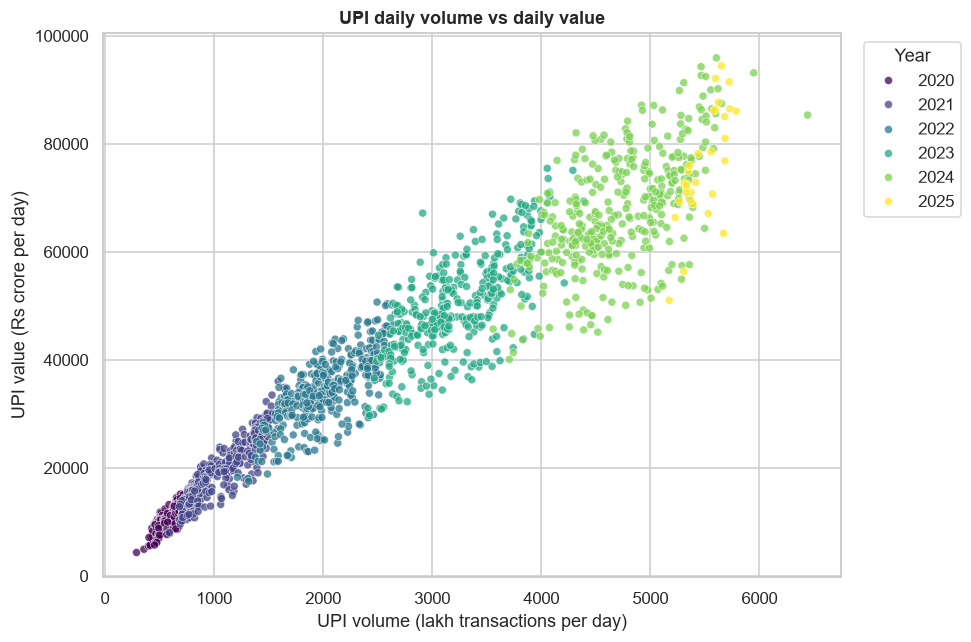

Correlation: 0.964


In [24]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='upi_vol', y='upi_val', hue='year', palette='viridis', alpha=0.75, s=28)
plt.title('UPI daily volume vs daily value')
plt.xlabel('UPI volume (lakh transactions per day)')
plt.ylabel('UPI value (Rs crore per day)')
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("Correlation:", round(df['upi_vol'].corr(df['upi_val']), 3))

**Interpretation:** UPI volume and value are very strongly related (correlation 0.96). Later years sit at the top right, showing growth in both. The relationship is not perfectly straight, because value grew more slowly than volume as the average ticket size fell.

## 3.11 Card payments: credit vs debit

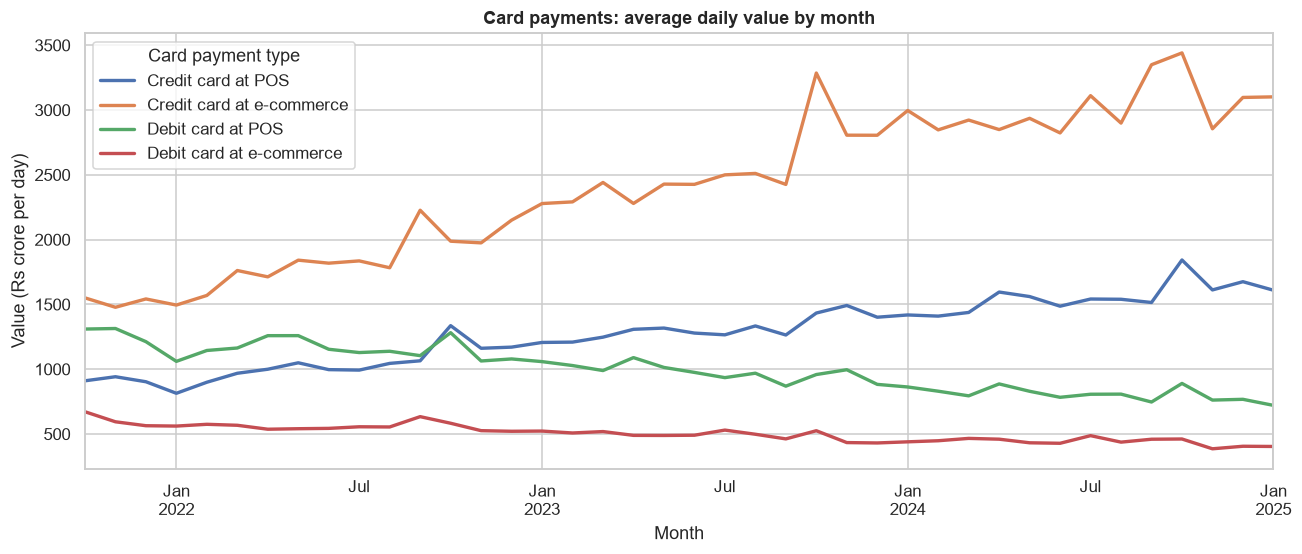

,Credit card at POS,Credit card at e-commerce,Debit card at POS,Debit card at e-commerce
year,,,,
2021,918.0,1524.0,1278.0,610.0
2022,1042.0,1848.0,1153.0,558.0
2023,1313.0,2542.0,980.0,491.0
2024,1553.0,3012.0,814.0,442.0
2025,1609.0,3101.0,721.0,404.0


In [25]:
# Card columns are available from Oct 2021 onwards
cards = df[df['date'] >= '2021-10-01']
card_cols = {'credit_card_at_pos_val': 'Credit card at POS',
             'credit_card_at_e_commerce_val': 'Credit card at e-commerce',
             'debit_card_at_pos_val': 'Debit card at POS',
             'debit_card_at_e_commerce_val': 'Debit card at e-commerce'}
card_m = cards.groupby(cards['date'].dt.to_period('M'))[list(card_cols)].mean()
card_m.index = card_m.index.to_timestamp()
card_m = card_m.rename(columns=card_cols)

ax = card_m.plot(figsize=(12, 5.2), linewidth=2.2)
ax.set_title('Card payments: average daily value by month')
ax.set_xlabel('Month')
ax.set_ylabel('Value (Rs crore per day)')
ax.legend(title='Card payment type')
plt.tight_layout()
plt.show()

cards.groupby('year')[list(card_cols)].mean().rename(columns=card_cols).round(0)

**Interpretation:** Credit and debit cards are moving in opposite directions. Between 2021 and 2024, average daily **credit card value grew by 98% at e-commerce (₹1,524 → ₹3,012 crore) and 69% at POS (₹918 → ₹1,553 crore)**, while **debit card value fell by 36% at POS (₹1,278 → ₹814 crore) and 28% at e-commerce (₹610 → ₹442 crore)**. Note that 2021 covers only Oct–Dec, because card data starts in October 2021.

## 3.12 UPI vs ATM withdrawals

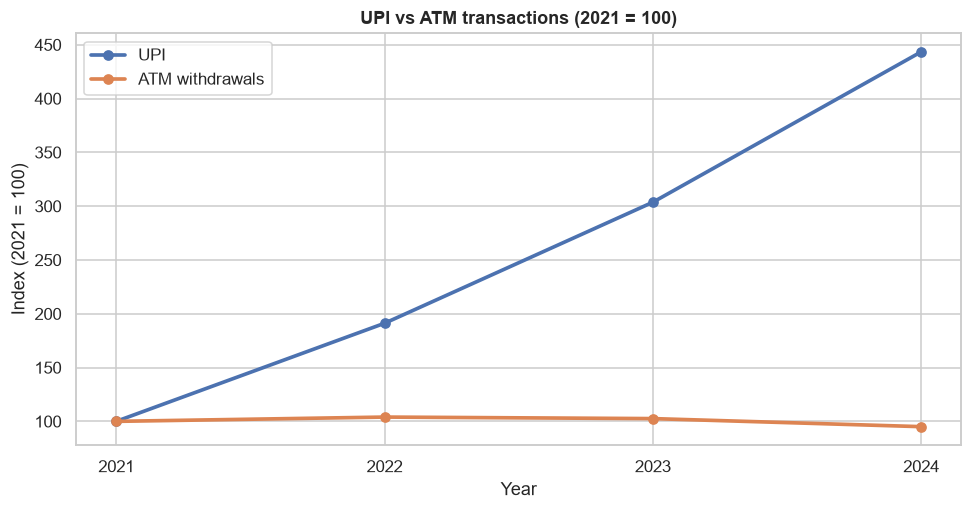

,UPI,ATM withdrawals
year,,
2021,100.0,100.0
2022,191.0,104.0
2023,304.0,103.0
2024,443.0,95.0


In [26]:
# Index each series to 2021 = 100 so very different sizes can be compared
idx = full.groupby('year')[['upi_vol', 'nfs_through_atms_vol']].mean()
idx = idx / idx.iloc[0] * 100
idx.columns = ['UPI', 'ATM withdrawals']

ax = idx.plot(marker='o', linewidth=2.4, figsize=(9, 4.8))
ax.set_title('UPI vs ATM transactions (2021 = 100)')
ax.set_xlabel('Year')
ax.set_ylabel('Index (2021 = 100)')
ax.set_xticks(idx.index)
plt.tight_layout()
plt.show()
idx.round(0)

**Interpretation:** Indexed to 2021 = 100, UPI volume reached 443 in 2024, while ATM transactions slipped to 95. People are moving from cash to digital payments.

# 4. Key insights
1. **UPI growth is huge but slowing.** UPI volume rose 4.4× from 2021 to 2024 (about 39 to 172 billion transactions), but yearly growth slowed from 91% to 59% to 46%.
2. **Volume and value tell different stories.** In 2024 UPI made up 85.5% of transactions but only 8.8% of value, while RTGS was 0.1% of transactions and 69% of value.
3. **UPI payments are getting smaller.** The average UPI ticket fell about 22%, from ₹1,848 (2021) to ₹1,433 (2024), so value is growing more slowly than volume (3.4× vs 4.4×).
4. **UPI never takes a day off.** UPI volume is steady across the week, while NEFT and RTGS fall sharply on weekends, since business payments follow working days.
5. **Cash is giving way to digital, and credit cards to debit cards.** UPI volume grew 4.4× while ATM transactions fell about 5%. Credit card value grew by 69–98% while debit card value fell by 28–36%.
6. **Everyday-payment services are growing fast.** Bill payments grew 3.9× and FASTag 1.8×, while IMPS has levelled off.
7. **Volumes peak in the festive season.** December is the highest month in every year, and the busiest day was 31 October 2024, around Diwali.

# 5. Conclusion and recommendations
India's digital payments grew rapidly between 2020 and 2025, led by UPI, which now handles most transactions by count. It is the system of small, frequent payments (average about ₹1,400), whereas large-value payments still go through RTGS and NEFT. Cash withdrawals and debit cards are losing ground, while credit cards, bill payments and toll payments are expanding.

**Recommendations**
- **Banks and fintechs:** because the average UPI payment is getting smaller, revenue will depend on scale and on extra services, not on payment size.
- **Infrastructure teams:** plan capacity for festive peaks, since the busiest days were in the Diwali period.
- **Card issuers:** credit cards at e-commerce are growing fastest, which suggests focusing offers there.
- **Next steps:** build a forecast of UPI volume, and update the analysis as more recent RBI data becomes available.

**Limitations:** the data is national-level and daily, so it cannot explain individual behaviour. 2020 and 2025 are partial years. Correlations here show association, not cause.